In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n = 50
temp = rng.uniform(-5, 45, n)
demand = 40 + 0.08 * (temp - 22)**2 + rng.normal(0, 4, n)

data=pd.DataFrame({
    'TEMPERATURE':temp.round(2),
    'DEMAND':demand.round(2)
})

Text(0, 0.5, 'demand')

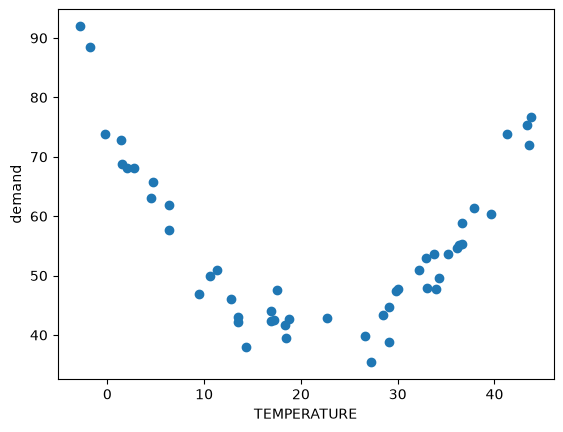

In [9]:
plt.scatter(data['TEMPERATURE'],data['DEMAND'])
plt.xlabel('TEMPERATURE');plt.ylabel('demand')

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score
X = data[['TEMPERATURE']]             
y = data['DEMAND']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

model=LinearRegression()
LINEAR=model.fit(X_train,y_train)
LINEAR_TRAIN_PREDICTION=model.predict(X_train)
LINEAR_R2_SCORE_train=r2_score(y_train,LINEAR_TRAIN_PREDICTION)

LINEAR_TEST_PREDICTION=model.predict(X_test)
LINEAR_R2_SCORE_test=r2_score(y_test,LINEAR_TEST_PREDICTION)


poly=PolynomialFeatures(degree=2)
X_train_poly=poly.fit_transform(X_train)
X_test_poly=poly.transform(X_test)

poly_model=LinearRegression().fit(X_train_poly,y_train)

poly_R2_SCORE_train = r2_score(y_train, poly_model.predict(X_train_poly))
poly_R2_SCORE_test  = r2_score(y_test,  poly_model.predict(X_test_poly))

# poly_linear_train_prediction = model


print('Linear     train/test:', round(LINEAR_R2_SCORE_train, 3), round(LINEAR_R2_SCORE_test, 3))
print('Polynomial train/test:', round(poly_R2_SCORE_train, 3),  round(poly_R2_SCORE_test, 3))

Linear     train/test: 0.02 0.051
Polynomial train/test: 0.941 0.96
